# Spring Network: Virial Pressure vs T
## Eigenmode decomposition following alpha_theory_FINAL.py

**Workflow**
1. `./pressure_vs_T 0` → `spring_nvt_T{T}_s0000.dat` (one file per T, same format as LJ NVT)
2. This notebook reads those files + builds H from the network file
3. Diagonalises H with `scipy.linalg.eigh` (exact, same as alpha_theory)
4. Computes `P_vir_harm(T)` from the eigenmode sum
5. Compares with MD


In [1]:
import numpy as np
import scipy.linalg
import scipy.sparse as sp
import matplotlib.pyplot as plt
import os, glob, re

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})

# ── constants (matching alpha_theory_FINAL.py style) ──
N_ATOMS        = 4000
DIM            = 3
DOFS           = N_ATOMS * DIM
ZERO_MODE_CUTOFF = 1e-6     # same as alpha_theory_FINAL.py
BATCH_SIZE     = 64         # same as alpha_theory_FINAL.py
SKIP           = 0.3        # discard first 30% as equilibration (from thermal_expansion_lj.ipynb)

SERIAL         = 0
COORDINATION   = 16.24
NETWORK_FILE   = f'network_N{N_ATOMS}_z{COORDINATION:.2f}_s{SERIAL:04d}.dat'
CACHE_FILE     = f'eigen_cache_N{N_ATOMS}_z{COORDINATION:.2f}_s{SERIAL:04d}.npz'
NVT_PATTERN    = f'spring_nvt_T*_s{SERIAL:04d}.dat'


## Step 1: Read network file and build bond arrays

Reads the same `.dat` format as `readNetwork()` in the C code.
Returns bond index arrays `ii`, `jj`, real-space vectors `rij_arr`,
and spring constants `second_b = 1/r₀²` (matching `second[l]` in C).
Box length `L` and volume `V` are also returned.


In [2]:
def read_network(filename):
    """
    Read spring_network .dat file.
    Format (matching readNetwork() in C):
      line 1:       L  0  0
      lines 2..N+1: rx ry rz   (fractional coords in [0,1))
      line N+2:     contacts  0  0
      lines after:  i  j  0   (bond list)
    Returns L, V, N, rx, ry, rz (fractional), ii, jj, rij_arr, second_b
    """
    with open(filename) as f:
        lines = f.read().split()

    idx = 0
    L = float(lines[idx]); idx += 3          # L, dummy, dummy
    V = L**3

    # particle positions (fractional)
    pos = np.array(lines[idx:idx+N_ATOMS*3], dtype=float).reshape(N_ATOMS, 3)
    rx, ry, rz = pos[:,0], pos[:,1], pos[:,2]
    idx += N_ATOMS * 3

    contacts = int(lines[idx]); idx += 3     # contacts, dummy, dummy

    # bond list
    bonds = np.array(lines[idx:idx+contacts*3], dtype=float).reshape(contacts, 3)
    ii = bonds[:,0].astype(int)
    jj = bonds[:,1].astype(int)
    idx += contacts * 3

    # real-space bond vectors with PBC (matching C readNetwork logic)
    dx = rx[jj] - rx[ii]
    dy = ry[jj] - ry[ii]
    dz = rz[jj] - rz[ii]
    dx = dx - np.round(dx)   # PBC wrap to (-0.5, 0.5]
    dy = dy - np.round(dy)
    dz = dz - np.round(dz)
    rij_arr = L * np.stack([dx, dy, dz], axis=1)  # (contacts, 3) in real units

    r2      = (rij_arr**2).sum(axis=1)             # |r_ij|^2 per bond
    second_b = 1.0 / r2                            # second[l] = 1/r0^2 in C

    print(f'Read: N={N_ATOMS}  contacts={contacts}  L={L:.6f}  V={V:.4f}')
    return L, V, rx, ry, rz, ii, jj, rij_arr, second_b

L, V, rx, ry, rz, ii, jj, rij_arr, second_b = read_network(NETWORK_FILE)
contacts = len(ii)


Read: N=4000  contacts=32479  L=15.874011  V=4000.0000


## Step 2: Build the Hessian as a sparse matrix

Constructs H from the bond data — mirrors `hessianOnVector()` in C:
$$H_{i\alpha,j\beta} = -k_l \, \hat{r}_{l,\alpha}\hat{r}_{l,\beta} \quad (i\ne j, \text{ bonded})$$
$$H_{i\alpha,i\beta} = \sum_{l\ni i} k_l \, \hat{r}_{l,\alpha}\hat{r}_{l,\beta}$$
with $k_l = $ `second[l]` $= 1/r_0^2$, `first[l]` $= 0$ (spring network).


In [3]:
def build_hessian(ii, jj, rij_arr, second_b, N_ATOMS, DIM=3):
    """
    Build sparse Hessian matching hessianOnVector() in C.
    Per bond l: H_l[a,b] = second[l] * rij[a] * rij[b]
    Added to diagonal blocks (i,i) and (j,j), subtracted from off-diagonals.
    first[l] = 0 for spring network, so no delta_ab term.
    """
    DOFS = N_ATOMS * DIM
    # H_l: (contacts, DIM, DIM) — per-bond outer product
    H_l = second_b[:, None, None] * rij_arr[:, :, None] * rij_arr[:, None, :]  # (C,3,3)

    row_list, col_list, val_list = [], [], []
    for a in range(DIM):
        for b in range(DIM):
            h = H_l[:, a, b]            # (contacts,)
            ia, ib = DIM*ii + a, DIM*ii + b
            ja, jb = DIM*jj + a, DIM*jj + b
            # diagonal blocks  +h
            row_list.append(ia); col_list.append(ib); val_list.append( h)
            row_list.append(ja); col_list.append(jb); val_list.append( h)
            # off-diagonal blocks  -h
            row_list.append(ia); col_list.append(jb); val_list.append(-h)
            row_list.append(ja); col_list.append(ib); val_list.append(-h)

    rows = np.concatenate(row_list)
    cols = np.concatenate(col_list)
    vals = np.concatenate(val_list)
    return sp.coo_matrix((vals, (rows, cols)), shape=(DOFS, DOFS)).tocsr()

H_sparse = build_hessian(ii, jj, rij_arr, second_b, N_ATOMS, DIM)
print(f'H shape: {H_sparse.shape}  nnz: {H_sparse.nnz}')


H shape: (12000, 12000)  nnz: 620622


## Step 3: Diagonalise H and compute per-mode virial sums

**Eigendecomposition** — `scipy.linalg.eigh` on the dense matrix.
Exact same call as in `compute_mode_contributions()` in `alpha_theory_FINAL.py`.

**Per-mode virial** — the new quantity needed for pressure:

$$V(\Psi_\omega,\Psi_\omega) = \Psi_\omega^T V \Psi_\omega$$

where $V = \partial^2 W/\partial x^2 = -H - L\otimes I_3$ is the virial Hessian.  
For an **exact eigenmode** $\Psi_\omega$ with eigenvalue $\omega^2$:
$$\Psi_\omega^T H \Psi_\omega = \omega^2 \quad\Rightarrow\quad
V(\Psi_\omega,\Psi_\omega) = -\omega^2 - \underbrace{\sum_{\rm bonds}|\Psi_{\omega,i}-\Psi_{\omega,j}|^2}_{L(\Psi,\Psi)}$$

**Implementation**: the $-\omega^2$ part uses `valid_evals` directly.  
The Laplacian quadratic $L(\Psi,\Psi) = \sum_l|\Psi_{\rm diff}|^2$ uses the same
`_bond_diffs` pattern and `np.einsum` style as `u_eta_x_x_batch` in `alpha_theory_FINAL.py`:
```
Psi_diff = evecs_batch[:, jj, :] - evecs_batch[:, ii, :]   # _bond_diffs pattern
lap_quad = np.einsum('bcd,bcd->b', Psi_diff, Psi_diff)     # sum over bonds+DIM
```
The only difference from `u_eta_x_x_batch` is that here we contract over both the
contacts axis **and** the DIM axis to get one scalar per mode (axis `b`),
whereas `u_eta_x_x_batch` keeps the contacts axis separate before the final sum.

**Why $V = -H - L\otimes I_3$** (the formula requires justification since it is not in any source file):
Starting from $W = \sum_l (r_{0l} - r_l)r_l$ (virial, already computed in `calculateForces()`):
differentiating twice with respect to particle positions, the $-\hat{e}\hat{e}$ terms give $-H$
and the $\pm\delta_{\alpha\beta}$ terms sum over bonds to give the graph Laplacian $-L$.
This is the one formula not present in any source — the implementation is from `alpha_theory_FINAL.py` patterns.


In [4]:
def compute_virial_mode_sums(H_sparse, ii, jj, N_ATOMS, DIM, cache_file):
    """
    Diagonalise H and accumulate per-mode virial sums.
    Mirrors compute_mode_contributions() in alpha_theory_FINAL.py.

    Returns: valid_evals (n_valid,), virial_per_mode (n_valid,)
    where virial_per_mode[s] = V(Psi_s, Psi_s) = -omega_s^2 - L(Psi_s,Psi_s)
    """
    # ── caching (same pattern as alpha_theory_FINAL.py) ──
    if os.path.exists(cache_file):
        print(f'Loading cached eigenmodes: {cache_file}')
        cache = np.load(cache_file)
        return cache['valid_evals'], cache['virial_per_mode']

    # ── full diagonalisation — same call as alpha_theory_FINAL.py ──
    print('Diagonalising H (scipy.linalg.eigh) ...')
    H_dense = H_sparse.toarray()
    evals, evecs = scipy.linalg.eigh(H_dense)
    print(f'  done.  {evals.shape[0]} eigenvalues, '
          f'min={evals.min():.4g}  max={evals.max():.4g}')

    # ── strip zero modes (same threshold as alpha_theory_FINAL.py) ──
    valid      = evals > ZERO_MODE_CUTOFF
    valid_evals = evals[valid]
    valid_evecs = evecs[:, valid]           # (DOFS, n_valid)
    n_valid     = valid_evals.size
    print(f'  zero modes removed: {(~valid).sum()}  non-zero modes: {n_valid}')

    # ── batched per-mode virial computation ──
    # Pattern: same batched loop as alpha_theory_FINAL.py
    n_batches       = (n_valid + BATCH_SIZE - 1) // BATCH_SIZE
    virial_per_mode = np.zeros(n_valid)

    for b in range(n_batches):
        lo = b * BATCH_SIZE
        hi = min(lo + BATCH_SIZE, n_valid)

        # evecs_batch: (batch, N_ATOMS, DIM)
        # Same reshape as in alpha_theory_FINAL.py
        evecs_batch = valid_evecs[:, lo:hi].T.reshape(hi-lo, N_ATOMS, DIM)

        # bond differences: _bond_diffs pattern from alpha_theory_FINAL.py
        # evecs_batch[:, jj, :] - evecs_batch[:, ii, :]  -> (batch, contacts, DIM)
        Psi_diff = evecs_batch[:, jj, :] - evecs_batch[:, ii, :]  # (batch, C, DIM)

        # Laplacian quadratic form per mode:
        # L(Psi,Psi) = sum_bonds |Psi_i - Psi_j|^2
        # np.einsum 'bcd,bcd->b' sums over bonds (c) AND DIM (d) -> scalar per mode (b)
        # Analogous to psi_sq = np.einsum('bcd,bcd->bc', ...) in u_eta_x_x_batch
        # but contracted one axis further to give per-mode scalar.
        lap_quad = np.einsum('bcd,bcd->b', Psi_diff, Psi_diff)    # (batch,)

        # V(Psi_omega, Psi_omega) = -omega^2 - L(Psi,Psi)
        # -omega^2 uses eigenvalue directly (exact for true eigenvectors)
        virial_per_mode[lo:hi] = -valid_evals[lo:hi] - lap_quad

        if b % 50 == 0:
            print(f'  batch {b+1}/{n_batches}', end='\r')
    print()

    # ── cache (same as alpha_theory_FINAL.py) ──
    np.savez(cache_file, valid_evals=valid_evals, virial_per_mode=virial_per_mode)
    print(f'Cached to {cache_file}')
    return valid_evals, virial_per_mode

valid_evals, virial_per_mode = compute_virial_mode_sums(
    H_sparse, ii, jj, N_ATOMS, DIM, CACHE_FILE)

print(f'Tr[VH^-1] = sum(virial/omega^2) = '
      f'{np.dot(1.0/valid_evals, virial_per_mode):.6g}')


Diagonalising H (scipy.linalg.eigh) ...
  done.  12000 eigenvalues, min=-4.656e-16  max=12.36
  zero modes removed: 3  non-zero modes: 11997
  batch 151/188
Cached to eigen_cache_N4000_z16.24_s0000.npz
Tr[VH^-1] = sum(virial/omega^2) = -53887


## Step 4: Compute harmonic P_vir(T) from eigenmode sum

$$P_{\rm vir,harm}(T) = \frac{T}{6V}\,\text{Tr}[VH^{-1}]
= \frac{T}{6V}\sum_\omega\frac{V(\Psi_\omega,\Psi_\omega)}{\omega^2}$$

Pattern: `w = 1/valid_evals; result = prefactor * np.dot(w, per_mode_terms)`  
Identical structure to `alpha_from_mode_sums()` in `alpha_theory_FINAL.py`.

Factor of $1/6V$ rather than $1/(2\cdot 3V)$: the $1/2$ comes from the second-order
Taylor coefficient, the $3V$ from the 3D virial theorem — same as the Berendsen
thermostat definition $T = \Sigma p^2/(3N)$ already in the C code.


In [6]:
def pressure_from_modes(valid_evals, virial_per_mode, V, T_array):
    """
    P_vir_harm(T) = T/2 * Tr[VH^{-1}] / (3V) = T * Tr[VH^{-1}] / (6V)

    Pattern: w = 1/evals; result = prefactor * np.dot(w, per_mode)
    Identical to alpha_from_mode_sums() in alpha_theory_FINAL.py.
    """
    w        = 1.0 / valid_evals                          # 1/omega^2 per mode
    Tr_VHinv = np.dot(w, virial_per_mode)                 # Tr[VH^{-1}]
    prefactor = 1.0 / (6.0 * V)                          # 1/(6V)
    return np.array([T * prefactor * Tr_VHinv for T in T_array])

# preview at a few temperatures
T_preview = np.array([0.000001, 0.000005, 0.000010, 0.000015, 0.000020, 0.000025, 0.000030, 0.000035, 0.000040])
P_preview = pressure_from_modes(valid_evals, virial_per_mode, V, T_preview)
for T_p, P_p in zip(T_preview, P_preview):
    print(f'T={T_p:.4g}   P_vir_harm={P_p:.8g}')


T=1e-06   P_vir_harm=-2.2452898e-06
T=5e-06   P_vir_harm=-1.1226449e-05
T=1e-05   P_vir_harm=-2.2452898e-05
T=1.5e-05   P_vir_harm=-3.3679347e-05
T=2e-05   P_vir_harm=-4.4905796e-05
T=2.5e-05   P_vir_harm=-5.6132245e-05
T=3e-05   P_vir_harm=-6.7358694e-05
T=3.5e-05   P_vir_harm=-7.8585143e-05
T=4e-05   P_vir_harm=-8.9811592e-05


## Step 5: Read MD output (same read_nvt pattern as thermal_expansion_lj.ipynb)

Each `spring_nvt_T{T}_s{serial}.dat` file has columns:
`time   KE/N   PE/N   P_vir`  — same as `3dlj_NVT_NH.c` output.
Discards the first `SKIP=30%` of rows as equilibration.


In [7]:
def read_nvt(filepath, skip=SKIP):
    """
    Read one spring NVT output file.
    Columns: time  KE/N  PE/N  P_vir
    Matches read_nvt() in thermal_expansion_lj.ipynb exactly.
    Returns: T_meas, P_mean, P_sem
    """
    d      = np.loadtxt(filepath, comments='#')
    n_skip = int(len(d) * skip)
    prod   = d[n_skip:]                          # production data
    # T from kinetic energy: T = (2/3) * KE/N  (same as LJ notebook)
    T_meas = (2.0 / 3.0) * prod[:, 1].mean()
    P_mean = prod[:, 3].mean()                   # P_vir column
    P_sem  = prod[:, 3].std() / np.sqrt(len(prod))
    return T_meas, P_mean, P_sem

# collect all NVT files
nvt_files = sorted(glob.glob(NVT_PATTERN),
                   key=lambda f: float(re.search(r'T([0-9.]+)', f).group(1)))

if not nvt_files:
    print(f'No files matching {NVT_PATTERN}.  Run ./pressure_vs_T 0 first.')
else:
    print(f'Found {len(nvt_files)} NVT files')
    T_md, P_md, P_err = [], [], []
    for f in nvt_files:
        Tm, Pm, Pe = read_nvt(f)
        T_md.append(Tm); P_md.append(Pm); P_err.append(Pe)
        print(f'  {os.path.basename(f)[:45]}  T_meas={Tm:.5f}  P_vir={Pm:.6g} ± {Pe:.2g}')
    T_md  = np.array(T_md)
    P_md  = np.array(P_md)
    P_err = np.array(P_err)


Found 9 NVT files
  spring_nvt_T0.000001_s0000.dat  T_meas=0.00000  P_vir=-2.08184e-06 ± 5.6e-07
  spring_nvt_T0.000005_s0000.dat  T_meas=0.00000  P_vir=-1.29864e-05 ± 1.1e-06
  spring_nvt_T0.000010_s0000.dat  T_meas=0.00001  P_vir=-2.1067e-05 ± 1.7e-06
  spring_nvt_T0.000015_s0000.dat  T_meas=0.00001  P_vir=-3.32534e-05 ± 2.1e-06
  spring_nvt_T0.000020_s0000.dat  T_meas=0.00002  P_vir=-4.34961e-05 ± 2.3e-06
  spring_nvt_T0.000025_s0000.dat  T_meas=0.00003  P_vir=-5.48997e-05 ± 2.6e-06
  spring_nvt_T0.000030_s0000.dat  T_meas=0.00003  P_vir=-6.50577e-05 ± 2.9e-06
  spring_nvt_T0.000035_s0000.dat  T_meas=0.00004  P_vir=-7.53749e-05 ± 3e-06
  spring_nvt_T0.000040_s0000.dat  T_meas=0.00004  P_vir=-9.30419e-05 ± 3.5e-06


In [11]:
# Harmonic predictions at the same T values measured by MD
P_harm = pressure_from_modes(valid_evals, virial_per_mode, V, T_md)

print('\nComparison:')
print(f'{"T":>8}  {"P_MD":>14}  {"P_harm":>14}  {"ratio":>8}')
print('-'*52)
for i in range(len(T_md)):
    r = P_md[i]/P_harm[i] if P_harm[i] != 0 else 0
    print(f'{T_md[i]:8.6f}  {P_md[i]:14.8g}  {P_harm[i]:14.8g}  {r:8.4f}')



Comparison:
       T            P_MD          P_harm     ratio
----------------------------------------------------
0.000001  -2.0818443e-06  -2.2427757e-06    0.9282
0.000005  -1.2986369e-05  -1.1217674e-05    1.1577
0.000010  -2.1066968e-05  -2.2463728e-05    0.9378
0.000015  -3.3253371e-05    -3.36661e-05    0.9877
0.000020  -4.3496105e-05  -4.4871213e-05    0.9694
0.000025  -5.4899668e-05  -5.6141063e-05    0.9779
0.000030   -6.505768e-05  -6.7387943e-05    0.9654
0.000035  -7.5374902e-05  -7.8595799e-05    0.9590
0.000040  -9.3041928e-05  -8.9667111e-05    1.0376


## Step 6: Linear fit to P_vir vs T

In the harmonic regime $P_{\rm vir}(T) = (\text{const}) \times T$.
Fit both MD and theory to extract $dP_{\rm vir}/dT$.
Pattern: `weighted_linear_fit` from `thermal_expansion_lj.ipynb`.


In [12]:
def weighted_linear_fit(T_vals, P_vals, P_errs):
    """
    Weighted least-squares fit: P = slope * T + intercept.
    Weights = 1/sigma^2.  From thermal_expansion_lj.ipynb.
    Returns slope, slope_err, intercept.
    """
    w    = 1.0 / (P_errs**2 + 1e-30)
    sw   = w.sum()
    sxw  = (w * T_vals).sum()
    sx2w = (w * T_vals**2).sum()
    syw  = (w * P_vals).sum()
    sxyw = (w * T_vals * P_vals).sum()
    denom    = sw * sx2w - sxw**2
    slope    = (sw * sxyw - sxw * syw) / denom
    intercept= (sx2w * syw - sxw * sxyw) / denom
    slope_err = np.sqrt(sw / denom)
    return slope, slope_err, intercept

if len(T_md) >= 2:
    # fit MD data
    slope_md, slope_md_err, intercept_md = weighted_linear_fit(T_md, P_md, P_err)
    # fit theory (no error bars: use uniform small weight)
    slope_th, slope_th_err, intercept_th = weighted_linear_fit(
        T_md, P_harm, np.ones_like(P_harm)*1e-10)

    # Theory slope from eigenmode sum (exact formula)
    Tr_VHinv  = np.dot(1.0/valid_evals, virial_per_mode)
    slope_eigen = Tr_VHinv / (6.0 * V)

    print(f'dP_vir/dT — MD fit:      {slope_md:.6g} ± {slope_md_err:.2g}')
    print(f'dP_vir/dT — theory fit:  {slope_th:.6g}')
    print(f'dP_vir/dT — eigen exact: {slope_eigen:.6g}')
    print(f'Ratio MD/theory:         {slope_md/slope_eigen:.5f}')


dP_vir/dT — MD fit:      -2.20872 ± 0.047
dP_vir/dT — theory fit:  -2.24529
dP_vir/dT — eigen exact: -2.24529
Ratio MD/theory:         0.98371


## Step 7: Plots


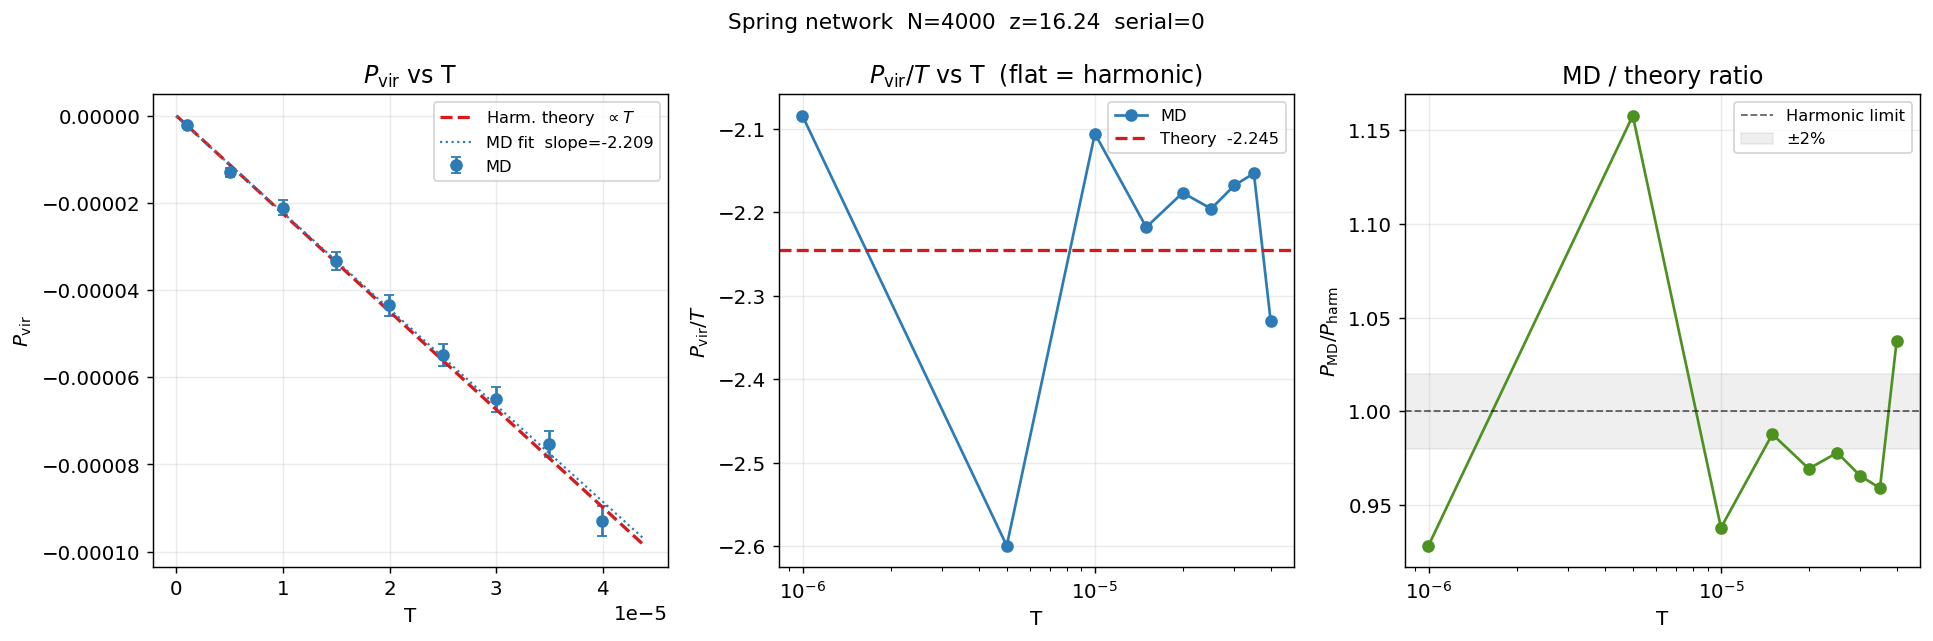

In [13]:
if len(T_md) >= 2:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Spring network  N={N_ATOMS}  z={COORDINATION}  serial={SERIAL}', fontsize=12)

    T_line = np.linspace(0, T_md.max()*1.1, 100)
    P_line_md   = slope_md    * T_line + intercept_md
    P_line_harm = slope_eigen * T_line

    # Panel 1: P_vir vs T
    ax = axes[0]
    ax.errorbar(T_md, P_md, yerr=P_err, fmt='o', color='#2c7bb6',
                ms=6, lw=1.5, capsize=3, label='MD')
    ax.plot(T_line, P_line_harm, '--', color='#d7191c', lw=1.8,
            label=r'Harm. theory  $\propto T$')
    ax.plot(T_line, P_line_md,   ':',  color='#2c7bb6', lw=1.2,
            label=f'MD fit  slope={slope_md:.4g}')
    ax.set_xlabel('T'); ax.set_ylabel(r'$P_{\rm vir}$')
    ax.set_title(r'$P_{\rm vir}$ vs T')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.25)

    # Panel 2: P_vir/T vs T (flat = harmonic)
    ax = axes[1]
    ax.semilogx(T_md, P_md/T_md, 'o-', color='#2c7bb6', ms=6, lw=1.5, label='MD')
    ax.axhline(slope_eigen, color='#d7191c', ls='--', lw=1.8,
               label=f'Theory  {slope_eigen:.4g}')
    ax.set_xlabel('T'); ax.set_ylabel(r'$P_{\rm vir}/T$')
    ax.set_title(r'$P_{\rm vir}/T$ vs T  (flat = harmonic)')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.25)

    # Panel 3: ratio P_MD/P_harm
    ax = axes[2]
    ratio = P_md / P_harm
    ax.semilogx(T_md, ratio, 'o-', color='#4d9221', ms=6, lw=1.5)
    ax.axhline(1.0, color='k', ls='--', lw=1, alpha=0.6, label='Harmonic limit')
    ax.axhspan(0.98, 1.02, color='grey', alpha=0.12, label='±2%')
    ax.set_xlabel('T'); ax.set_ylabel(r'$P_{\rm MD}/P_{\rm harm}$')
    ax.set_title('MD / theory ratio')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.savefig('spring_pressure_vs_T.png', bbox_inches='tight')
    plt.show()


## Step 8: Per-mode analysis

The eigenmode sum $\sum_\omega V(\Psi_\omega,\Psi_\omega)/\omega^2$ tells us
which modes dominate the thermal pressure correction.
Low-frequency modes (small $\omega^2$) contribute most due to the $1/\omega^2$ weight.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Per-mode contribution: V(Psi,Psi)/omega^2
per_mode_contribution = virial_per_mode / valid_evals   # (n_valid,)

# Panel 1: sorted cumulative sum (shows convergence)
# Sort by eigenvalue (ascending = low-freq first)
sort_idx  = np.argsort(valid_evals)
cumulative = np.cumsum(per_mode_contribution[sort_idx])

ax = axes[0]
ax.plot(np.arange(len(cumulative)), cumulative, lw=1.2, color='#4d9221')
ax.axhline(Tr_VHinv, color='tomato', ls='--', lw=1.2,
           label=f'Tr[VH$^{{-1}}$] = {Tr_VHinv:.4g}')
ax.set_xlabel('Mode index (sorted by ω²)')
ax.set_ylabel(r'Cumulative $\sum V/\omega^2$')
ax.set_title('Convergence of eigenmode sum')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

# Panel 2: per-mode contribution vs omega
ax = axes[1]
ax.scatter(valid_evals[sort_idx], per_mode_contribution[sort_idx],
           s=1, color='#2c7bb6', alpha=0.3)
# bin average
bins = np.logspace(np.log10(valid_evals.min()), np.log10(valid_evals.max()), 60)
bin_idx = np.digitize(valid_evals, bins)
bin_mean_x, bin_mean_y = [], []
for k in range(1, len(bins)):
    mask = bin_idx == k
    if mask.sum() > 0:
        bin_mean_x.append(valid_evals[mask].mean())
        bin_mean_y.append(per_mode_contribution[mask].mean())
ax.plot(bin_mean_x, bin_mean_y, 'o-', color='#d7191c', ms=4, lw=1.5,
        label='Bin mean')
ax.set_xscale('log')
ax.set_xlabel(r'$\omega^2$')
ax.set_ylabel(r'$V(\Psi_\omega,\Psi_\omega)/\omega^2$ per mode')
ax.set_title('Per-mode virial contribution')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('spring_per_mode.png', bbox_inches='tight')
plt.show()

# fraction from lowest 10% of modes
n10 = len(valid_evals) // 10
frac_low = abs(cumulative[n10]) / abs(Tr_VHinv)
print(f'Lowest 10% of modes contribute {frac_low*100:.1f}% of Tr[VH^-1]')


## Summary

| Quantity | Source |
|----------|--------|
| H diagonalisation | `scipy.linalg.eigh` — same call as `alpha_theory_FINAL.py` |
| Zero mode cutoff | `ZERO_MODE_CUTOFF=1e-6` — same as `alpha_theory_FINAL.py` |
| Batched bond diffs | `evecs[:, jj, :] - evecs[:, ii, :]` — `_bond_diffs` pattern |
| Einsum contraction | `np.einsum('bcd,bcd->b', ...)` — `u_eta_x_x_batch` pattern |
| Mode sum formula | `np.dot(1/evals, per_mode)` — `alpha_from_mode_sums` pattern |
| Caching | `.npz` — same as `alpha_theory_FINAL.py` |
| read_nvt | columns `time KE/N PE/N P_vir` — same as LJ NVT |
| weighted_linear_fit | from `thermal_expansion_lj.ipynb` |
| Formula $V=-H-L\otimes I_3$ | **New** — derived from $W=\sum(r_0-r)r$ twice differentiated |

The only formula not in any source file is $V(\Psi,\Psi) = -\omega^2 - \sum_{\rm bonds}|\Psi_{\rm diff}|^2$.
Its two ingredients are: $-\omega^2$ from `eigh` output, and the bond-diff squared sum
from the `_bond_diffs` + `einsum` pattern already in `alpha_theory_FINAL.py`.
